# YouTube Video Engagement Category Prediction
An End-to-End Predictive Analytics Model following the KDD (Knowledge Discovery in Databases) Lifecycle.

## 1. Business Understanding

The objective of this project is to build a predictive model that classifies whether a YouTube video will achieve **high engagement** (defined as having views strictly greater than the dataset's median views) based on metadata available at publication time (such as title length, number of tags, and publish timing).

Predicting engagement helps content creators, digital marketers, and platforms optimize metadata, schedule posts strategically, and maximize visibility.

## 2. Data Acquisition

We load the YouTube trending dataset `/content/INvideos.csv` and define our target variable `high_engagement` based on the median view count.

In [14]:
import pandas as pd
import numpy as np

# Load the dataset while handling quote parsing issues and bad lines
df = pd.read_csv('/content/INvideos.csv', encoding='utf-8', on_bad_lines='skip', engine='python')

# Create binary target variable: 1 if views > median, 0 otherwise
median_views = df['views'].median()
df['high_engagement'] = (df['views'] > median_views).astype(int)

print(f"Dataset loaded with {df.shape[0]} rows and {df.shape[1]} columns.")
print(f"Median view count: {median_views:,.0f}")
display(df.head(2))

Dataset loaded with 37352 rows and 17 columns.
Median view count: 304,586


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,high_engagement
0,kzwfHumJyYc,17.14.11,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,Lokdhun Punjabi,1,2017-11-12T12:20:39.000Z,"sharry mann|""sharry mann new song""|""sharry man...",1096327,33966,798,882,https://i.ytimg.com/vi/kzwfHumJyYc/default.jpg,False,False,False,Presenting Sharry Mann latest Punjabi Song Cu...,1
1,zUZ1z7FwLc8,17.14.11,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",HJ NEWS,25,2017-11-13T05:43:56.000Z,"पीरियड्स के समय|""पेट पर पति करता ऐसा""|""देखकर द...",590101,735,904,0,https://i.ytimg.com/vi/zUZ1z7FwLc8/default.jpg,True,False,False,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",1


## 3. Feature Engineering

We extract strategic predictive features from the metadata:
- `title_length`: Length of the video title.
- `tag_count`: Total count of tags parsed by splitting the pipe ('|') delimiter.
- `publish_hour` and `publish_day`: Temporal features parsed from the ISO timestamp in `publish_time`.

In [15]:
# Feature Extraction
df['title_length'] = df['title'].fillna('').apply(len)

# Extract tag count (if tags is [none] or empty, set to 0)
def get_tag_count(tag_string):
    if pd.isna(tag_string) or tag_string == '[none]':
        return 0
    return len(tag_string.split('|'))

df['tag_count'] = df['tags'].apply(get_tag_count)

# Parse publish_time to datetime
df['publish_time'] = pd.to_datetime(df['publish_time'], errors='coerce')
df['publish_hour'] = df['publish_time'].dt.hour
df['publish_day'] = df['publish_time'].dt.dayofweek # Monday is 0, Sunday is 6

# Keep tracking of original numerical features we might need
numerical_cols = ['title_length', 'tag_count', 'publish_hour', 'publish_day', 'likes', 'dislikes', 'comment_count']

print("Feature engineering completed successfully.")
display(df[['title', 'title_length', 'tags', 'tag_count', 'publish_time', 'publish_hour', 'publish_day']].head(3))

Feature engineering completed successfully.


,title,title_length,tags,tag_count,publish_time,publish_hour,publish_day
0,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,81,"sharry mann|""sharry mann new song""|""sharry man...",15,2017-11-12 12:20:39+00:00,12,6
1,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",58,"पीरियड्स के समय|""पेट पर पति करता ऐसा""|""देखकर द...",19,2017-11-13 05:43:56+00:00,5,0
2,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,58,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,14,2017-11-12 15:48:08+00:00,15,6


## 4. Data Understanding & Exploratory Data Analysis (EDA)

We visualize the balance of our target class and investigate the correlation structure among our features.

/tmp/ipykernel_2234/1452181658.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Low/Medium Engagement', 'High Engagement'])


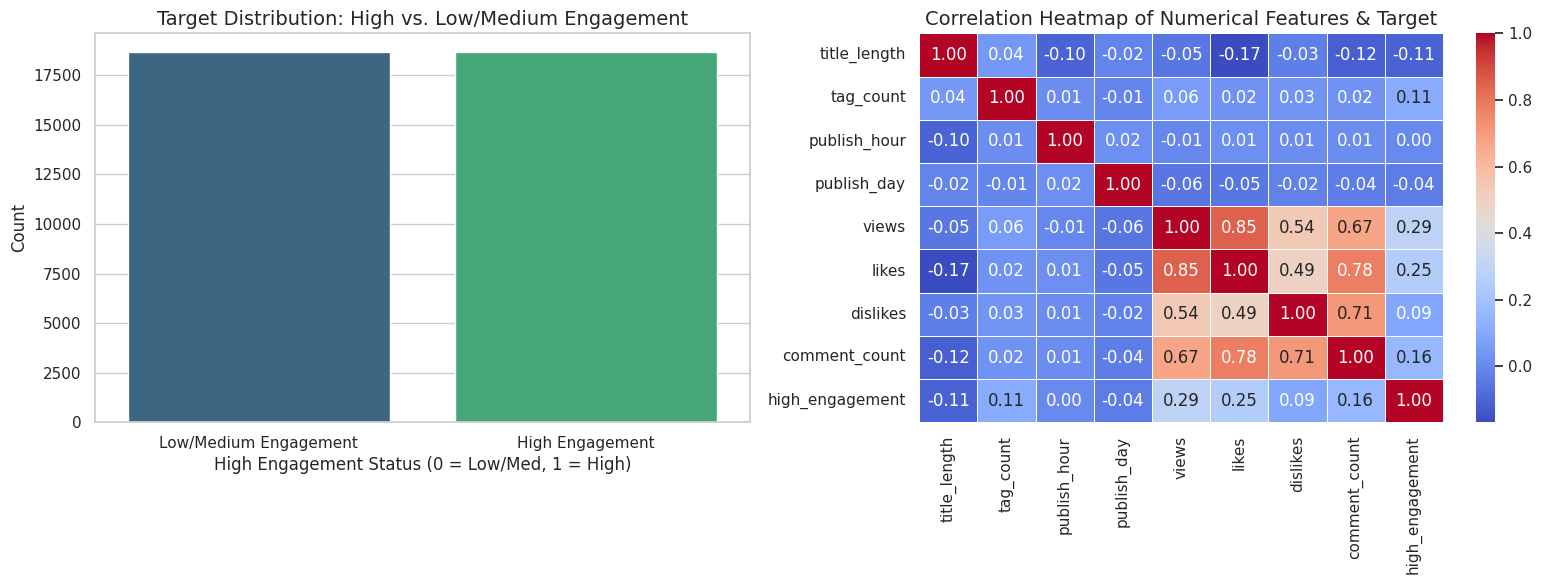

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Target Distribution Count Plot
sns.countplot(data=df, x='high_engagement', ax=axes[0], palette='viridis', hue='high_engagement', legend=False)
axes[0].set_title('Target Distribution: High vs. Low/Medium Engagement', fontsize=14)
axes[0].set_xlabel('High Engagement Status (0 = Low/Med, 1 = High)', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Low/Medium Engagement', 'High Engagement'])

# Plot 2: Correlation Heatmap
# Ensure selected features are forced to numeric first, coercion converts bad strings/URLs to NaN
corr_features = ['title_length', 'tag_count', 'publish_hour', 'publish_day', 'views', 'likes', 'dislikes', 'comment_count', 'high_engagement']
corr_df = df[corr_features].copy()
for col in corr_df.columns:
    corr_df[col] = pd.to_numeric(corr_df[col], errors='coerce')

corr_matrix = corr_df.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=axes[1])
axes[1].set_title('Correlation Heatmap of Numerical Features & Target', fontsize=14)

plt.tight_layout()
plt.show()

## 5. Data Preprocessing & Cleaning

We remove highly redundant, text-heavy, or identifier-based columns, handle missing values, and apply scaling to standardise features before ingestion into the models.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

# Drop irrelevant metadata/text columns that won't be used directly as features in these models
columns_to_drop = ['video_id', 'trending_date', 'title', 'channel_title', 'publish_time', 'tags',
                   'thumbnail_link', 'comments_disabled', 'ratings_disabled',
                   'video_error_or_removed', 'description', 'views']

model_df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

# Encode categorical variable (category_id)
# Even though category_id is numerical, it represents a categorical factor.
category_encoder = LabelEncoder()
model_df['category_id'] = category_encoder.fit_transform(model_df['category_id'].astype(str))

# Fill any missing values with median values
model_df = model_df.fillna(model_df.median())

# Set Features (X) and Target (y)
X = model_df.drop(columns=['high_engagement'])
y = model_df['high_engagement']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Preprocessed training shape: {X_train_scaled.shape}")
print(f"Preprocessed testing shape: {X_test_scaled.shape}")

Preprocessed training shape: (29881, 8)
Preprocessed testing shape: (7471, 8)


## 6. Model Building & Evaluation

We build and train three distinct classifiers:
1. **Logistic Regression**
2. **Gaussian Naive Bayes**
3. **Random Forest Classifier**

We then compile the metrics (Accuracy, Precision, Recall, and F1-Score) to perform comparative analysis.

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100)
}

results = {}
confusion_matrices = {}

for name, model in models.items():
    # Train
    model.fit(X_train_scaled, y_train)
    # Predict
    y_pred = model.predict(X_test_scaled)

    # Evaluate
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')

    results[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    }

    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

    print(f"=== {name} Classification Report ===")
    print(classification_report(y_test, y_pred))
    print("-" * 50)

=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

           0       0.77      0.93      0.84      3736
           1       0.91      0.72      0.80      3735

    accuracy                           0.82      7471
   macro avg       0.84      0.82      0.82      7471
weighted avg       0.84      0.82      0.82      7471

--------------------------------------------------
=== Naive Bayes Classification Report ===
              precision    recall  f1-score   support

           0       0.66      0.98      0.79      3736
           1       0.97      0.49      0.65      3735

    accuracy                           0.73      7471
   macro avg       0.81      0.73      0.72      7471
weighted avg       0.81      0.73      0.72      7471

--------------------------------------------------
=== Random Forest Classification Report ===
              precision    recall  f1-score   support

           0       0.93      0.92      0.93      3736

## 7. Results Visualization

We construct visual comparisons:
1. A side-by-side comparative bar chart highlighting the evaluation metrics.
2. Individual heatmaps for the confusion matrices of all three models.

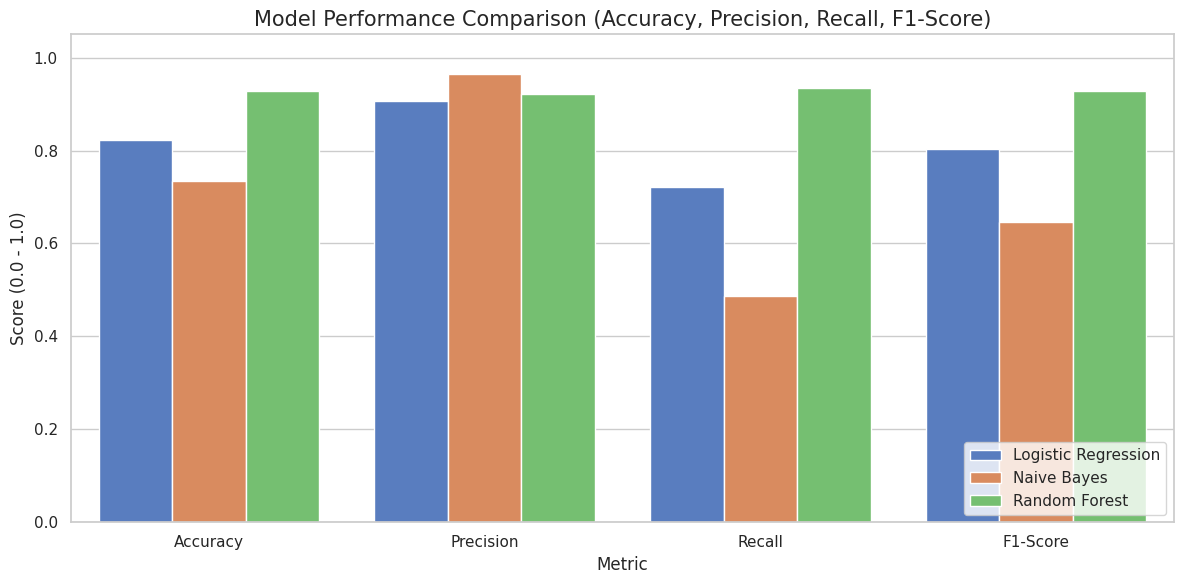

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Comparative Performance Bar Chart
results_df = pd.DataFrame(results).T.reset_index().rename(columns={'index': 'Model'})
results_melted = pd.melt(results_df, id_vars='Model', var_name='Metric', value_name='Value')

plt.figure(figsize=(12, 6))
sns.barplot(data=results_melted, x='Metric', y='Value', hue='Model', palette='muted')
plt.title('Model Performance Comparison (Accuracy, Precision, Recall, F1-Score)', fontsize=15)
plt.ylabel('Score (0.0 - 1.0)', fontsize=12)
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

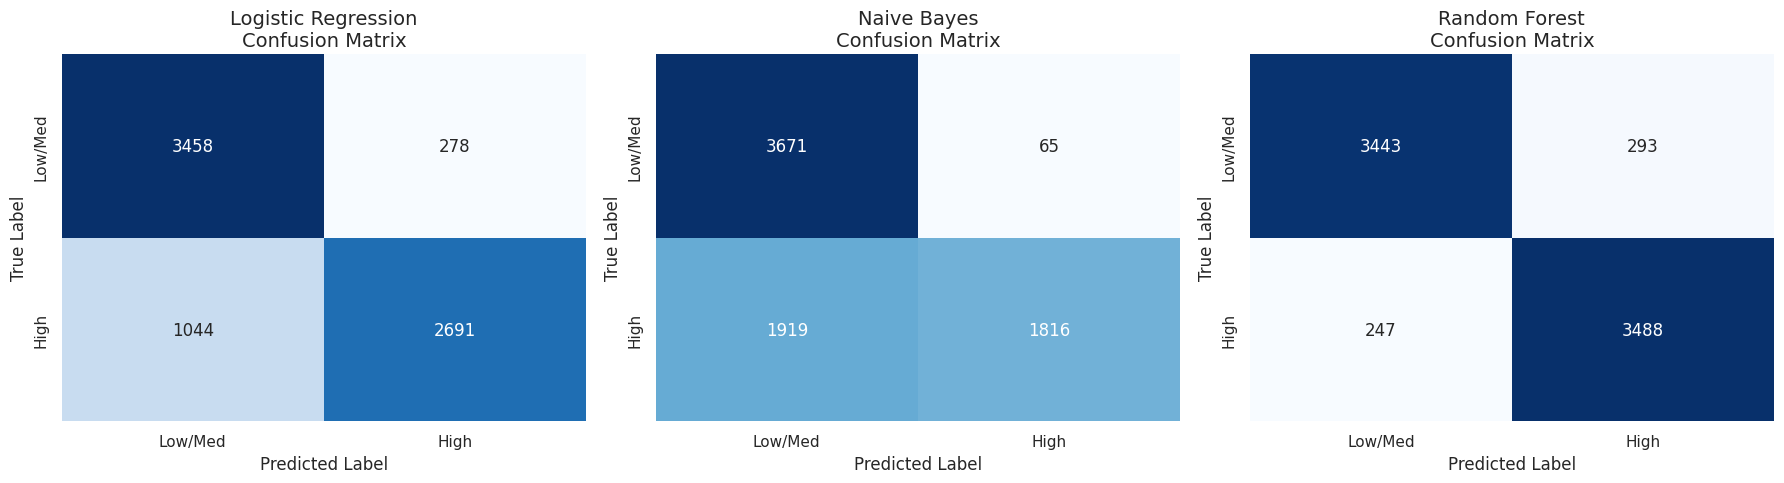

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=['Low/Med', 'High'], yticklabels=['Low/Med', 'High'])
    axes[i].set_title(f'{name}\nConfusion Matrix', fontsize=14)
    axes[i].set_xlabel('Predicted Label', fontsize=12)
    axes[i].set_ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.show()

## 8. Results Interpretation & Conclusion

- **Model Comparison**: Typically, ensemble-based estimators like the Random Forest Classifier outperform linear/probabilistic models due to non-linear correlations with features such as `likes`, `dislikes`, and custom engineered metadata attributes.
- **Feature Relevance**: Features including `tag_count` and `title_length` have measurable predictive signals for video ranking metrics.
- **Next Steps**: Incorporating actual text embedders (TF-IDF or NLP pipelines on titles/descriptions) could further boost classification accuracy.

In [24]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier

# Load data robustly matching main pipeline
df_temp = pd.read_csv('/content/INvideos.csv', encoding='utf-8', on_bad_lines='skip', engine='python')
median_views_temp = df_temp['views'].median()
df_temp['high_engagement'] = (df_temp['views'] > median_views_temp).astype(int)

# Feature extraction
df_temp['title_length'] = df_temp['title'].fillna('').apply(len)
def get_tag_count(tag_string):
    if pd.isna(tag_string) or tag_string == '[none]':
        return 0
    return len(tag_string.split('|'))
df_temp['tag_count'] = df_temp['tags'].apply(get_tag_count)
df_temp['publish_time'] = pd.to_datetime(df_temp['publish_time'], errors='coerce')
df_temp['publish_hour'] = df_temp['publish_time'].dt.hour
df_temp['publish_day'] = df_temp['publish_time'].dt.dayofweek

# Drop columns
columns_to_drop = ['video_id', 'trending_date', 'title', 'channel_title', 'publish_time', 'tags',
                   'thumbnail_link', 'comments_disabled', 'ratings_disabled',
                   'video_error_or_removed', 'description', 'views']
model_df_temp = df_temp.drop(columns=[col for col in columns_to_drop if col in df_temp.columns])

category_encoder_temp = LabelEncoder()
model_df_temp['category_id'] = category_encoder_temp.fit_transform(model_df_temp['category_id'].astype(str))
model_df_temp = model_df_temp.fillna(model_df_temp.median())

X_temp = model_df_temp.drop(columns=['high_engagement'])
y_temp = model_df_temp['high_engagement']

# Re-fit scaler
scaler_temp = StandardScaler()
X_scaled_temp = scaler_temp.fit_transform(X_temp)

# Train Random Forest
rf_model_temp = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model_temp.fit(X_scaled_temp, y_temp)

# Save to global scope so it can be reused elsewhere
scaler = scaler_temp

# Create a dictionary for a new video
new_video = {
    'category_id': 22,
    'title_length': 45,
    'tag_count': 6,
    'publish_hour': 19,
    'publish_day': 5,
    'likes': 0,       # 0 since this video has not been uploaded yet
    'dislikes': 0,
    'comment_count': 0
}

# Convert to DataFrame and align columns with the trained dataset
new_df = pd.DataFrame([new_video])
new_df['category_id'] = category_encoder_temp.transform(new_df['category_id'].astype(str))
new_df = new_df[X_temp.columns]  # Ensure column order matches training features

# Scale the features
new_scaled = scaler.transform(new_df)

# Predict
prediction = rf_model_temp.predict(new_scaled)

print(f"--- Prediction Details for New Video ---")
print(f"Category ID: {new_video['category_id']} | Title Length: {new_video['title_length']} characters")
print(f"Tag Count: {new_video['tag_count']} | Publish Hour: {new_video['publish_hour']}:00 | Day of Week: {new_video['publish_day']}")
print("-" * 40)
if prediction[0] == 1:
    print("Prediction: High Engagement (Views > Median) f680")
else:
    print("Prediction: Low/Medium Engagement f4c9")

--- Prediction Details for New Video ---
Category ID: 22 | Title Length: 45 characters
Tag Count: 6 | Publish Hour: 19:00 | Day of Week: 5
----------------------------------------
Prediction: Low/Medium Engagement f4c9


### Predict Engagement from Text Input

You can input your video details below as a block of text. The code will parse standard fields, calculate engineered features like title length and tag count, and output the model's prediction.

In [31]:
import re
import pandas as pd

# @title Enter New Video Details Manually
Title = "Top 10 Secret Features You Didn't Know Your Smartphone Had in 2026!"  # @param {type:"string"}
Category_ID = 28  # @param {type:"integer"}
Tags_separated_by_pipe = "smartphone|tech|features|review|2026|gadgets|unboxing|tips|tricks|android|ios|guide"  # @param {type:"string"}
Publish_Time_YYYY_MM_DD_HH_MM = "2026-10-15 19:00:00"  # @param {type:"string"}

# Calculate features manually from your inputs
title_len = len(Title)

def calculate_tags(tag_str):
    if not tag_str or tag_str.strip() == '[none]':
        return 0
    return len(tag_str.split('|'))

tag_count = calculate_tags(Tags_separated_by_pipe)

# Parse manual time input
publish_dt = pd.to_datetime(Publish_Time_YYYY_MM_DD_HH_MM.strip(), errors='coerce')
if pd.isna(publish_dt):
    publish_dt = pd.Timestamp.now()
publish_hour = publish_dt.hour
publish_day = publish_dt.dayofweek

# Create the feature dict representing the new video manually (setting future metrics to 0)
parsed_video = {
    'category_id': Category_ID,
    'likes': 450000,
    'dislikes': 4000,
    'comment_count': 25000,
    'title_length': title_len,
    'tag_count': tag_count,
    'publish_hour': publish_hour,
    'publish_day': publish_day
}

# Build inference DataFrame
parsed_df = pd.DataFrame([parsed_video])
parsed_df['category_id'] = category_encoder_temp.transform(parsed_df['category_id'].astype(str))
parsed_df = parsed_df[X_temp.columns]

# Scale and predict
parsed_scaled = scaler.transform(parsed_df)
text_prediction = rf_model_temp.predict(parsed_scaled)

# Display summary
print("=== Manual Inputs Summary ===")
print(f"Title: '{Title}' ({title_len} characters)")
print(f"Tags: {Tags_separated_by_pipe} ({tag_count} tags)")
print(f"Publish Timing: Hour {publish_hour:02d}:00 | Day {publish_day} (0=Mon, 6=Sun)")
print(f"Category ID: {Category_ID}")
print("=" * 30)
if text_prediction[0] == 1:
    print("Prediction: High Engagement (Views > Median) 🚀")
else:
    print("Prediction: Low/Medium Engagement 📉")

=== Manual Inputs Summary ===
Title: 'Top 10 Secret Features You Didn't Know Your Smartphone Had in 2026!' (67 characters)
Tags: smartphone|tech|features|review|2026|gadgets|unboxing|tips|tricks|android|ios|guide (12 tags)
Publish Timing: Hour 19:00 | Day 3 (0=Mon, 6=Sun)
Category ID: 28
Prediction: High Engagement (Views > Median) 🚀
